# 01 · Exploring GB electricity demand

What drives national demand (ND), and what does that mean for forecasting?
Inputs are the cleaned files from `python -m demand_forecast.data.clean`.

All timestamps are stored in UTC. For anything about *human behaviour* (hour of day,
weekday) we convert to UK local time, because people's routines follow the clock.

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from demand_forecast.config import PROJECT_ROOT, processed_dir

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = PROJECT_ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
P = processed_dir()

demand = pd.read_parquet(P / "demand_hourly.parquet")
half = pd.read_parquet(P / "demand_halfhourly.parquet")
wx = pd.read_parquet(P / "weather_actual.parquet")
wx_fc = pd.read_parquet(P / "weather_forecast.parquet")
wx_hist = pd.read_parquet(P / "weather_hist_forecast.parquet")
report = json.loads((P / "cleaning_report.json").read_text())

df = demand[["nd_mw"]].join(wx, how="inner").dropna(subset=["nd_mw"])
local = df.index.tz_convert("Europe/London")
df["hour"], df["dow"], df["month"], df["year"] = local.hour, local.dayofweek, local.month, local.year
df["gw"] = df["nd_mw"] / 1000
print(f"{len(df):,} hourly rows, {df.index[0]:%Y-%m-%d} → {df.index[-1]:%Y-%m-%d}")

49,967 hourly rows, 2021-01-01 → 2026-09-13


## 1. What did cleaning find?

In [2]:
d = report["demand"]
pd.Series({
    "raw half-hourly rows": d["raw_rows"],
    "clock-change days (46/50 periods)": d["clock_change_days"],
    "days with wrong period count": len(d["days_with_wrong_period_count"]),
    "duplicate rows": d["duplicate_rows"],
    "missing half-hours": d["missing_halfhours"],
    "outliers removed": d["outliers_removed"],
    "interpolated half-hours": d["interpolated_halfhours"],
    "hourly rows": d["hourly_rows"],
    "weather (actual) gap-hours filled": report["weather_actual"]["hours_with_gaps_before_fill"],
}, name="count").to_frame()

,count
raw half-hourly rows,99934
clock-change days (46/50 periods),11
days with wrong period count,0
duplicate rows,0
missing half-hours,0
outliers removed,0
interpolated half-hours,0
hourly rows,49967
weather (actual) gap-hours filled,1


### Clock changes, checked
On the spring change, local time skips 01:00–02:00, so the day has 46 half-hours; in autumn
it repeats an hour (50). In UTC both days are just a continuous run of timestamps.

In [3]:
days = pd.Series(half.index.tz_convert("Europe/London").date)
counts = days.value_counts().sort_index()
print("half-hours per local day:", counts.value_counts().sort_index().to_dict())
print("non-48 days:", [str(d) for d in counts[counts != 48].index][:6], "...")
step = pd.Series(half.index).diff().dropna()
print("UTC steps:", step.value_counts().to_dict())

half-hours per local day: {46: 6, 48: 2071, 50: 5}
non-48 days: ['2021-03-28', '2021-10-31', '2022-03-27', '2022-10-30', '2023-03-26', '2023-10-29'] ...
UTC steps: {Timedelta('0 days 00:30:00'): 99933}


## 2. Long-term trend

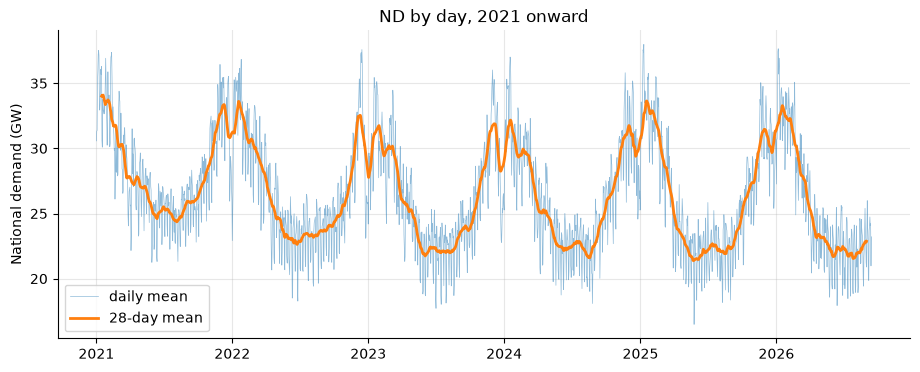

year,2021,2022,2023,2024,2025,2026
full-year mean GW,28.35,26.62,26.05,26.29,26.16,25.34
Jan-Aug mean GW,27.96,26.43,25.50,25.51,25.45,25.46


In [4]:
daily = df["gw"].resample("D").mean()
fig, ax = plt.subplots()
ax.plot(daily.index, daily, lw=0.5, alpha=0.5, label="daily mean")
ax.plot(daily.index, daily.rolling(28, center=True).mean(), lw=2, label="28-day mean")
ax.set_ylabel("National demand (GW)"); ax.set_title("ND by day, 2021 onward"); ax.legend()
fig.savefig(FIG / "trend.png", dpi=120, bbox_inches="tight"); plt.show()
# 2026 is a partial year, so compare like with like: the same Jan-Aug window every year.
pd.DataFrame({"full-year mean GW": df.groupby("year")["gw"].mean(),
              "Jan-Aug mean GW": df[df["month"] <= 8].groupby("year")["gw"].mean()}).round(2).T

Comparing the same January–August window each year (2026 only runs to mid-September),
ND drops ~2.5 GW (9%) from 2021 to 2023, then stays flat at ~25.5 GW through 2026.
Likely causes of the drop: the 2022 price shock, efficiency, and growing rooftop solar (which hides
demand from the transmission network). 2021 is also inflated by lockdown-era patterns
early in the year. **Forecasting implication:** 2021–22 describe a different system,
so models should weight recent data or include a trend term. The good news is that the
2024+ test period is stable.

## 3. Daily pattern: by hour of day

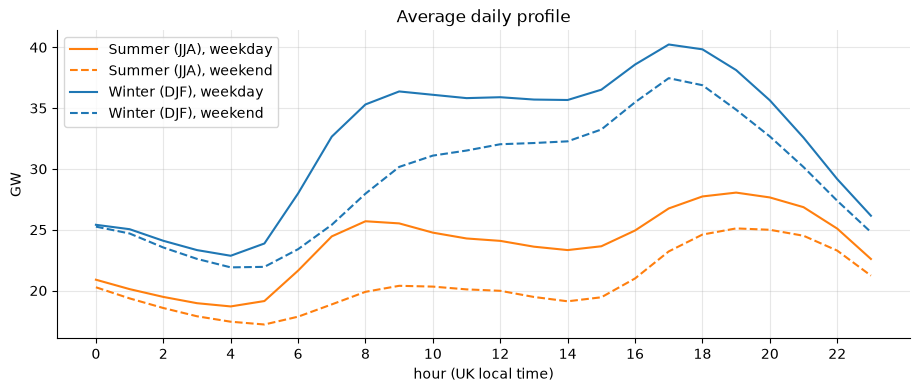

In [5]:
season = df["month"].map({12: "Winter (DJF)", 1: "Winter (DJF)", 2: "Winter (DJF)",
                           6: "Summer (JJA)", 7: "Summer (JJA)", 8: "Summer (JJA)"})
weekend = np.where(df["dow"] >= 5, "weekend", "weekday")
prof = df.assign(season=season, kind=weekend).dropna(subset=["season"])
prof = prof.groupby(["season", "kind", "hour"])["gw"].mean().unstack([0, 1])
fig, ax = plt.subplots()
for (s, k), col in prof.items():
    ax.plot(col.index, col, ls="-" if k == "weekday" else "--", label=f"{s}, {k}",
            color="tab:blue" if s.startswith("Winter") else "tab:orange")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour (UK local time)"); ax.set_ylabel("GW")
ax.set_title("Average daily profile"); ax.legend()
fig.savefig(FIG / "daily_profile.png", dpi=120, bbox_inches="tight"); plt.show()

Night trough around 04:00, morning ramp, and a **winter evening peak around 17:00–18:00**
(lighting + cooking + heating), ~40 GW on weekdays. Summer's evening peak is smaller and
later (~19:00, when it gets dark later), and summer has a midday dip from rooftop solar.
Weekends start later and lower. The shape depends strongly on hour,
weekday and season, so those are core features.

## 4. Weekly pattern

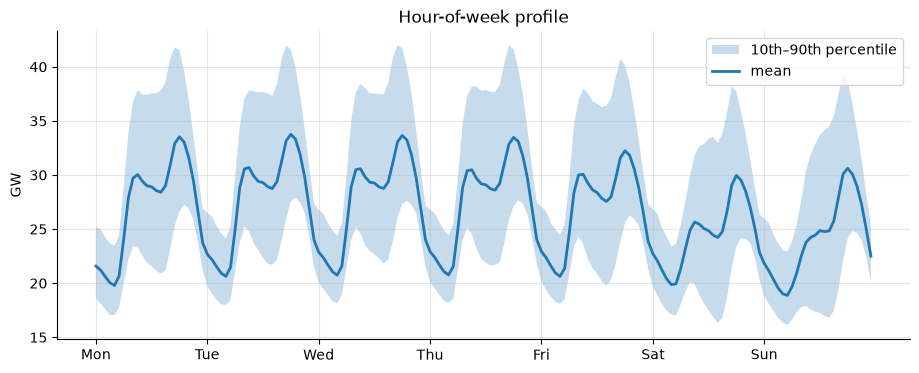

In [6]:
how = df["dow"] * 24 + df["hour"]
wk = df.groupby(how)["gw"].describe(percentiles=[0.1, 0.9])
fig, ax = plt.subplots()
ax.fill_between(wk.index, wk["10%"], wk["90%"], alpha=0.25, label="10th–90th percentile")
ax.plot(wk.index, wk["mean"], lw=2, label="mean")
ax.set_xticks(range(0, 168, 24), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_ylabel("GW"); ax.set_title("Hour-of-week profile"); ax.legend()
fig.savefig(FIG / "weekly_profile.png", dpi=120, bbox_inches="tight"); plt.show()

Mon–Fri look alike, Saturday is lower, Sunday lowest. This weekly cycle is why
**"same hour last week"** is a strong naive baseline: it automatically matches weekday and
hour. The wide band shows how much is left to explain, mostly by season and weather.

## 5. Yearly pattern

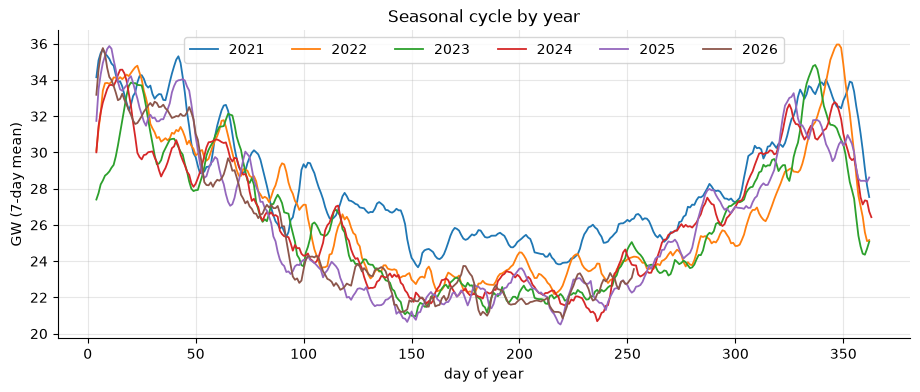

In [7]:
dd = daily.to_frame("gw")
dd["doy"], dd["year"] = dd.index.dayofyear, dd.index.year
fig, ax = plt.subplots()
for y, g in dd.groupby("year"):
    ax.plot(g["doy"], g["gw"].rolling(7, center=True).mean(), label=str(y), lw=1.3)
ax.set_xlabel("day of year"); ax.set_ylabel("GW (7-day mean)"); ax.set_title("Seasonal cycle by year")
ax.legend(ncol=6)
fig.savefig(FIG / "yearly.png", dpi=120, bbox_inches="tight"); plt.show()

Winter demand is about 1.5× summer. Each year's curve is lower than the last (the
trend), and the sharp dips are the Christmas/New Year weeks. Those need a holiday feature.

## 6. Temperature vs demand

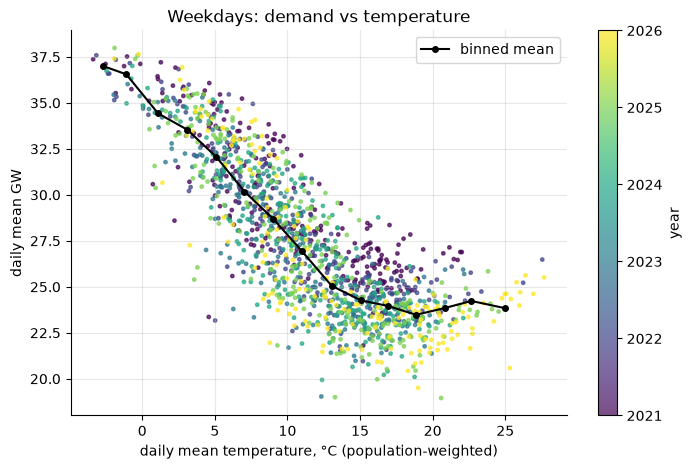

Below 15 °C: ~811 MW extra demand per 1 °C colder


In [8]:
dly = df.resample("D").agg({"gw": "mean", "temperature_2m": "mean", "dow": "first", "year": "first"})
wd = dly[dly["dow"] < 5].dropna()
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(wd["temperature_2m"], wd["gw"], c=wd["year"], s=6, cmap="viridis", alpha=0.7)
bins = pd.cut(wd["temperature_2m"], np.arange(-6, 28, 2))
binned = wd.groupby(bins, observed=True).agg(t=("temperature_2m", "mean"), gw=("gw", "mean"))
ax.plot(binned["t"], binned["gw"], "k-o", ms=4, label="binned mean")
plt.colorbar(sc, label="year"); ax.legend()
ax.set_xlabel("daily mean temperature, °C (population-weighted)"); ax.set_ylabel("daily mean GW")
ax.set_title("Weekdays: demand vs temperature")
fig.savefig(FIG / "temp_vs_demand.png", dpi=120, bbox_inches="tight"); plt.show()
slope = np.polyfit(wd.loc[wd.temperature_2m < 15, "temperature_2m"], wd.loc[wd.temperature_2m < 15, "gw"], 1)[0]
print(f"Below 15 °C: ~{-slope*1000:.0f} MW extra demand per 1 °C colder")

Classic **heating curve**: demand rises steadily as it gets colder (~0.8 GW per °C)
and bottoms out around 17–19 °C. Above ~20 °C there's only a small rise (fans, some
air-conditioning). Britain has little cooling load compared with hotter countries.
The relationship isn't a straight line, so tree models (XGBoost) handle it naturally,
while linear-ish models need a "heating degrees" feature like `max(0, 15.5 − T)`. The colour
gradient shows that the same temperature gives lower demand each year (the trend again).

## 7. Sunshine *lowers* ND

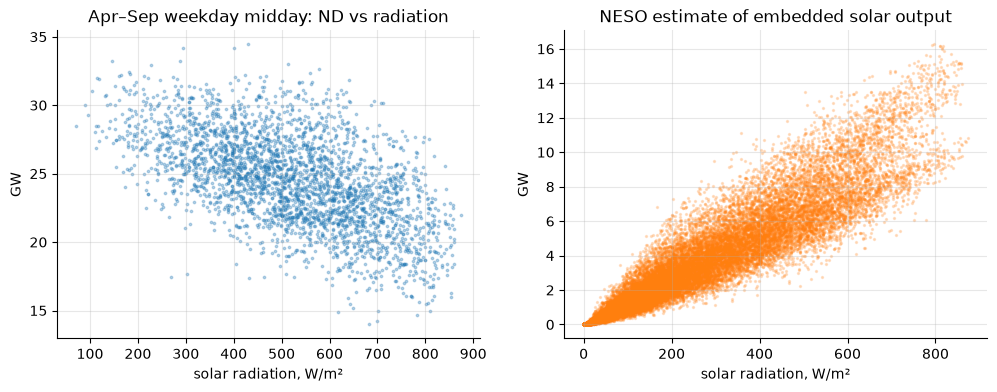

corr(ND, radiation) at summer weekday midday: -0.57


In [9]:
mid = df[(df["hour"].between(11, 14)) & (df["month"].between(4, 9)) & (df["dow"] < 5)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(mid["shortwave_radiation"], mid["gw"], s=3, alpha=0.3)
axes[0].set_xlabel("solar radiation, W/m²"); axes[0].set_ylabel("GW")
axes[0].set_title("Apr–Sep weekday midday: ND vs radiation")
sol = half["embedded_solar_mw"].resample("1h").mean().reindex(df.index) / 1000
axes[1].scatter(df["shortwave_radiation"], sol, s=2, alpha=0.2, color="tab:orange")
axes[1].set_xlabel("solar radiation, W/m²"); axes[1].set_ylabel("GW")
axes[1].set_title("NESO estimate of embedded solar output")
fig.savefig(FIG / "solar.png", dpi=120, bbox_inches="tight"); plt.show()
print("corr(ND, radiation) at summer weekday midday:", round(mid["gw"].corr(mid["shortwave_radiation"]), 2))

Rooftop solar output tracks radiation closely (right). Because ND only counts what flows
through the transmission network, that output shows up as *lower* ND (left).
**Radiation is a key weather feature**, especially for summer middays. (NESO's embedded
solar estimate isn't known in advance, so we won't use it as a feature; we use forecast
radiation instead.)

## 8. How wrong are weather forecasts?
This is why honest backtesting needs *forecast* weather. Below is the error of each weather
source compared with the reanalysis ("what actually happened"). All forecast sources use the
same ECMWF IFS model. Mixing models adds a systematic offset: the Met Office 2 km model is
~0.5 °C warmer than the reanalysis over London, which would look like forecast error but isn't.

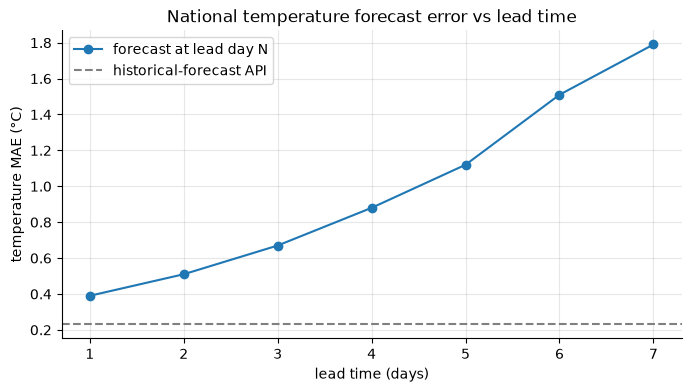

,temp MAE °C,radiation MAE W/m²,wind MAE km/h
historical_forecast (stitched),0.23,8.66,0.71
previous_runs day 1,0.39,12.89,1.00
previous_runs day 2,0.51,16.24,1.30
previous_runs day 3,0.67,19.86,1.76
previous_runs day 4,0.88,23.78,2.41
previous_runs day 5,1.12,28.03,2.92
previous_runs day 6,1.51,50.11,3.69
previous_runs day 7,1.79,56.34,4.05


In [10]:
def mae(a, b):
    j = pd.concat([a, b], axis=1, join="inner").dropna()
    return (j.iloc[:, 0] - j.iloc[:, 1]).abs().mean()

rows = {"historical_forecast (stitched)": {v: mae(wx_hist[v], wx[v]) for v in ["temperature_2m", "shortwave_radiation", "wind_speed_10m"]}}
for d, g in wx_fc.groupby(level="lead_day"):
    g = g.droplevel("lead_day")
    rows[f"previous_runs day {d}"] = {v: mae(g[v], wx[v]) for v in ["temperature_2m", "shortwave_radiation", "wind_speed_10m"]}
err = pd.DataFrame(rows).T.round(2)
err.columns = ["temp MAE °C", "radiation MAE W/m²", "wind MAE km/h"]
fig, ax = plt.subplots(figsize=(8, 4))
lead = err.iloc[1:]
ax.plot(range(1, 8), lead["temp MAE °C"], "o-", label="forecast at lead day N")
ax.axhline(err.iloc[0, 0], ls="--", color="grey", label="historical-forecast API")
ax.set_xlabel("lead time (days)"); ax.set_ylabel("temperature MAE (°C)"); ax.legend()
ax.set_title("National temperature forecast error vs lead time")
fig.savefig(FIG / "weather_forecast_error.png", dpi=120, bbox_inches="tight"); plt.show()
err

Temperature error grows steadily with lead time: 0.39 °C at day 1 to 1.79 °C at day 7.
The "historical forecast" API (0.23 °C) beats even the day-1 forecast, because it's built
from each run's first few hours. Its error isn't zero only because a forecast model and the
reanalysis never agree exactly. Evaluating a 7-day forecast with it, or with reanalysis,
would hide most of the real-world weather error.
Phase 4 measures how much that inflates scores.

The jump in radiation error at day 6 is real and comes from the source data: ECMWF's open
data drops from hourly to 3/6-hourly steps beyond ~5 days, so hourly radiation has to be
interpolated and loses the timing of cloud breaks.

## 9. How much does past demand tell us?

In [11]:
s = demand["nd_mw"].dropna()
lags = {"1 h": 1, "24 h": 24, "48 h": 48, "168 h (1 week)": 168, "336 h (2 weeks)": 336}
ac = pd.Series({k: s.autocorr(v) for k, v in lags.items()}, name="correlation with demand N hours earlier")
naive = {k: (s - s.shift(v)).abs().mean() / s.mean() * 100 for k, v in lags.items()}
pd.DataFrame({"autocorr": ac.round(3), "naive MAPE %": pd.Series(naive).round(1)})

,autocorr,naive MAPE %
1 h,0.962,4.8
24 h,0.910,7.0
48 h,0.835,9.9
168 h (1 week),0.896,7.8
336 h (2 weeks),0.857,9.0


In [12]:
# Yesterday vs last week, split by the weekday being forecast
ape = lambda lag: ((s - s.shift(lag)).abs() / s * 100)
dow = s.index.tz_convert("Europe/London").day_name()
by_dow = pd.DataFrame({"yesterday (24h) MAPE %": ape(24).groupby(dow).mean(),
                       "last week (168h) MAPE %": ape(168).groupby(dow).mean()})
by_dow.loc[["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]].round(1)

,yesterday (24h) MAPE %,last week (168h) MAPE %
time,,
Monday,11.6,8.4
Tuesday,5.7,7.3
Wednesday,4.5,7.4
Thursday,4.6,7.8
Friday,5.4,7.8
Saturday,11.4,8.3
Sunday,7.1,8.1


Demand 1 hour ago is a near-perfect guide, so 1h forecasts are the easy case.

On average, *yesterday* (7.0%) is a slightly better guess than *last week* (7.8%). But it
breaks down when the day type changes: Monday copies Sunday, and Saturday copies Friday.
Last week is consistent across weekdays. More importantly, it's the most recent same-hour
value that exists **for every horizon up to 7 days**, so one baseline works fairly at
1h, 24h and 168h. Phase 2 makes sure a 7-day forecast can't peek at the last 7 days.

## Takeaways for modelling
1. **Calendar matters most:** hour × weekday × season shape. Plus bank holidays and Christmas.
2. **Temperature** drives winter demand non-linearly (heating only). **Solar radiation** pulls ND down at midday.
3. **Trend:** ND fell ~9% from 2021 to 2023 and has been flat since, so recent data matters most.
4. **Lags:** extremely useful for short horizons, but must respect the horizon.
5. **Weather forecasts degrade with lead time.** Honest evaluation must use them.